# 01 · Ingesta, limpieza y reconciliación

Citi Bike Nueva York, enero–marzo 2024. El script `descargar_datos.py` consolida los 3 ZIP mensuales en un TSV, SQL Server lo carga con `BULK INSERT` y `etl.sp_limpiar` marca cada fila con su motivo de exclusión. Aquí se comprueba que Python y SQL Server cuentan exactamente lo mismo.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLAS = RAIZ / "reports" / "tablas"

def leer(nombre: str) -> pd.DataFrame:
    return pd.read_csv(TABLAS / f"{nombre}.csv")

def miles(x) -> str:
    return f"{x:,.0f}".replace(",", ".")

def dec(x, n=1) -> str:
    return f"{x:,.{n}f}".replace(",", "X").replace(".", ",").replace("X", ".")


## 1. Bitácora del ETL
Duración de cada etapa en la corrida que generó `reports/`.

In [2]:
bitacora = leer('bitacora_etl')
bitacora['segundos'] = (bitacora['duracion_ms'] / 1000).round(1)
bitacora[['etapa', 'filas_afectadas', 'segundos']]

,etapa,filas_afectadas,segundos
0,BULK_INSERT_STAGING,6672881,17.0
1,LIMPIEZA_Y_REGLAS_CALIDAD,6672881,1189.3
2,CARGA_MODELO_ESTRELLA_CCI,6653987,105.7
3,ESTRUCTURAS_E_INDICES_LABORATORIO,6653987,172.0
4,BENCHMARK_LABORATORIO_TUNING,26,467.1


## 2. Reconciliación Python vs. SQL Server
`data/cifras_control.json` lo calcula pandas leyendo los CSV originales; `resumen_limpieza.csv` sale de `rpt.resumen_limpieza_calidad`.

In [3]:
control = json.loads((RAIZ / 'data' / 'cifras_control.json').read_text(encoding='utf-8'))
limpieza = leer('resumen_limpieza')
sql = dict(zip(limpieza['estado_calidad'], limpieza['filas']))
comparacion = pd.DataFrame({'python': pd.Series(control['desglose_motivos']), 'sql_server': pd.Series(sql)})
comparacion['diferencia'] = comparacion['python'] - comparacion['sql_server']
print('Filas brutas:', miles(control['filas_totales_brutas']), '| válidas:', miles(control['filas_validas']),
      f"({dec(control['tasa_retencion_pct'], 2)} %)")
assert (comparacion['diferencia'] == 0).all()
comparacion

Filas brutas: 6.672.881 | válidas: 6.653.987 (99,72 %)


,python,sql_server,diferencia
VALIDO,6653987,6653987,0
SIN_ESTACION_O_COORD_DESTINO,13009,13009,0
DATOS_ORIGEN_INCOMPLETOS,5822,5822,0
DURACION_EXCESIVA_MAYOR_24H,63,63,0


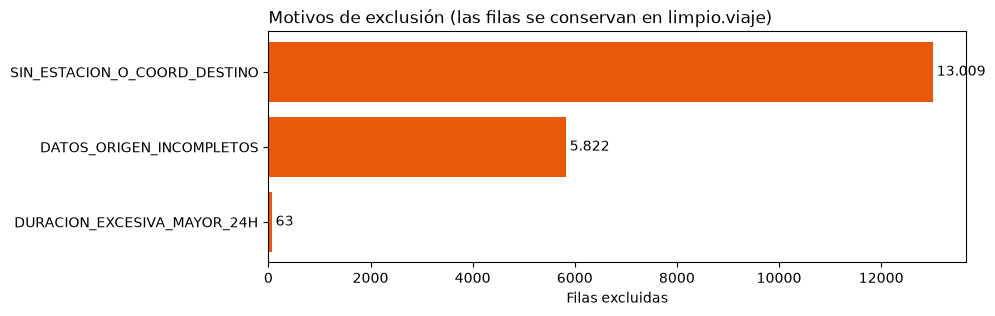

In [4]:
excl = limpieza[limpieza['estado_calidad'] != 'VALIDO'].sort_values('filas')
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(excl['estado_calidad'], excl['filas'], color='#ea580c')
for i, n in enumerate(excl['filas']):
    ax.text(n, i, ' ' + miles(n), va='center')
ax.set_xlabel('Filas excluidas')
ax.set_title('Motivos de exclusión (las filas se conservan en limpio.viaje)', loc='left')
plt.show()

**Lectura:** casi todas las exclusiones son viajes sin estación o coordenadas de destino (bicicletas que no se devolvieron en una estación o registros incompletos). Representan menos del 0,3 % del total, así que no sesgan el análisis; aun así quedan en `limpio.viaje` con su motivo para poder auditarlas.

## 3. Controles automáticos (`qa.sp_validar_calidad`)

In [5]:
qa = leer('controles_calidad')
print(f"{(qa['estado'] == 'OK').sum()} de {len(qa)} controles en OK")
qa.groupby('categoria')['estado'].value_counts().unstack(fill_value=0)

40 de 40 controles en OK


estado,OK
categoria,
Almacenamiento,1
Calidad,2
Dimensiones,3
Equivalencia SQL,11
Laboratorio,1
Query Store,4
Reconciliación,5
Rendimiento,11
Tipping point,2


In [6]:
qa[['orden', 'categoria', 'control', 'valor_observado', 'valor_esperado', 'estado']]

,orden,categoria,control,valor_observado,valor_esperado,estado
0,1,Reconciliación,Filas cargadas por BULK INSERT = filas en limp...,0.00,0.0,OK
1,2,Reconciliación,limpio.viaje = válidas + excluidas,0.00,0.0,OK
2,3,Reconciliación,dw.fact_viaje tiene exactamente las filas válidas,0.00,0.0,OK
3,4,Reconciliación,Las 4 tablas del laboratorio tienen exactament...,0.00,0.0,OK
4,5,Reconciliación,"Suma de duración idéntica en limpio, dw, rowst...",0.00,0.0,OK
5,6,Calidad,Cero viajes con duración <= 0 o > 86.400 s en ...,0.00,0.0,OK
6,7,Calidad,Cero falsos arranques (< 60 s en la misma esta...,0.00,0.0,OK
7,8,Dimensiones,Calendario de enero–marzo 2024 completo en dw....,91.00,91.0,OK
8,9,Dimensiones,Cero claves foráneas huérfanas en dw.fact_viaje,0.00,0.0,OK
9,10,Dimensiones,Cero ride_id duplicados entre los viajes válidos,0.00,0.0,OK
